# Per-family classifiers — which features distinguish each AMR gene family

One-vs-rest LightGBM per family (n≥10 sequences), with grouped cross-validation and two complementary importance measures.

**Design decisions locked in from discussion, not defaults picked here:**
- **Single-label, One-vs-Rest** — 84 independent binary classifiers (family X vs. everyone else), not multi-label. Multi-label was dropped: it would need either real sequences (for CD-HIT) or a working ID link from `sequence_id` to CARD's raw multi-family annotation, and neither exists in this data (checked directly — 0/6206 `sequence_id`s match CARD's Protein/DNA Accession columns).
- **No CD-HIT.** Cross-validation grouping instead uses feature-vector similarity as an approximate substitute — two sequences with near-identical composition are very likely near-identical sequences, since AAC/DPC/CTC/etc. are deterministic functions of the sequence itself. Threshold (1.0, standardized Euclidean distance) was chosen empirically: it sits right at the edge of the tight near-identical cluster in the nearest-neighbor distance distribution, before the distribution jumps into general within-family similarity — confirmed a looser threshold (3.0) collapses 73% of PDC beta-lactamase into a single CV group, which would break stratification for that family. This is an approximation, not equivalent to true sequence identity — a coincidence in composition isn't the same guarantee as actual sequence similarity.
- **Two-stage feature importance**, not naive permutation importance over all ~1035 features — timed directly at ~9 hours for 84 families, not viable. Gain importance (free, from the fitted model) shortlists candidates, permutation importance runs only on the shortlist.
- **SHAP is the primary importance signal, not permutation importance.** For families with very strong separation (e.g. qnr — confirmed AP=1.000 on held-out folds), permutation importance goes to exactly zero: the model has multiple redundant features that could each alone achieve perfect separation, so shuffling any one doesn't hurt the score. This isn't a bug — it's genuinely uninformative in that regime. SHAP doesn't have this blind spot (verified directly: still correctly ranks qnr's known top feature, `CTC_762`, first). Read permutation importance alongside each family's AP score — near-zero at AP≈1.0 means "redundant, not unimportant."

**Runtime:** designed for parallel execution across families (`joblib`, `n_jobs=-1`) — on a single core this is roughly 90 minutes for all 84 families; scales down close to linearly with cores available.

In [ ]:
!pip install shap

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 59.9/59.9 MB 1.2 MB/s  0:00:54 eta 0:00:010:00:020m
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.9/3.9 MB 559.7 kB/s  0:00:07550.7 kB/s eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5/5 [shap]━━━━━━ 4/5 [shap]]te]


In [ ]:
import numpy as np
import pandas as pd
from pathlib import Path
from joblib import Parallel, delayed

import lightgbm as lgb
import shap
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import roc_auc_score, average_precision_score
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import radius_neighbors_graph
from scipy.sparse.csgraph import connected_components

print(f"lightgbm {lgb.__version__} | shap {shap.__version__} | pandas {pd.__version__}")

lightgbm 4.7.0 | shap 0.52.0 | pandas 3.0.5


In [ ]:
# --- inputs: same two feature tables used throughout this analysis ---
PFEATURE_TABLE = Path("all_families_features.csv")
PROFET_TABLE   = Path("all_families_profet_features.csv")
OUTPUT_DIR = Path("results/family_classifiers")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

MIN_FAMILY_N = 10          # families below this can't support reliable one-vs-rest modelling
CV_GROUP_THRESHOLD = 1.0   # standardized-feature-space distance for near-duplicate grouping (chosen empirically, see markdown)
N_FOLDS = 5
N_REPEATS = 5              # permutation importance repeats
SHORTLIST_N = 80           # features passed from gain-importance triage to permutation importance
N_JOBS = -1                # parallel families; set to your allocated cores, not os.cpu_count()
LGB_PARAMS = dict(n_estimators=300, num_leaves=15, learning_rate=0.05,
                   is_unbalance=True, verbosity=-1, n_jobs=2)  # n_jobs=2 per model -- outer loop is where parallelism happens

In [ ]:
pf = pd.read_csv(PFEATURE_TABLE)
pr = pd.read_csv(PROFET_TABLE)
KEY = ["family", "sequence_id"]
d = pf.merge(pr, on=KEY, how="inner")
print(f"merged: {d.shape[0]} sequences x {d.shape[1]-2} features")

sizes = d["family"].value_counts()
qualifying = sizes[sizes >= MIN_FAMILY_N].index
d = d[d["family"].isin(qualifying)].reset_index(drop=True)
print(f"restricted to n>={MIN_FAMILY_N}: {d.shape[0]} sequences, {d['family'].nunique()} families")

merged: 6206 sequences x 1040 features
restricted to n>=10: 5479 sequences, 84 families


In [ ]:
meta = ["family", "sequence_id"]
X_df = d.drop(columns=meta).select_dtypes(include=[np.number]).copy()

# Known issue from earlier in this pipeline: PRI_* columns were median-imputed upstream
# for PDC beta-lactamase due to a systematic extraction failure. Re-null so they don't
# silently masquerade as real signal in this model either.
pri_cols = [c for c in X_df.columns if c.startswith("PRI_")]
X_df.loc[d["family"] == "PDC beta-lactamase", pri_cols] = np.nan

n_nan = int(X_df.isna().sum().sum())
X_df = X_df.fillna(X_df.median(numeric_only=True))
zero_var = X_df.columns[X_df.std(numeric_only=True) == 0]
X_df = X_df.drop(columns=zero_var)
print(f"imputed {n_nan} NaN cells, dropped {len(zero_var)} zero-variance columns")
print(f"final feature matrix: {X_df.shape}")

feat_names = X_df.columns.to_numpy()
X = X_df.values

imputed 15351 NaN cells, dropped 5 zero-variance columns
final feature matrix: (5479, 1035)


### CV grouping (approximate CD-HIT substitute)

Near-duplicate detection via nearest-neighbour distance in standardized feature space, not true sequence identity. Threshold=1.0 was chosen by inspecting the actual distance distribution (see markdown above) — re-derive this on your own data if the family composition changes substantially, don't assume 1.0 transfers automatically.

In [ ]:
X_scaled = StandardScaler().fit_transform(X)
graph = radius_neighbors_graph(X_scaled, radius=CV_GROUP_THRESHOLD, mode="connectivity", n_jobs=-1)
n_groups, cv_groups = connected_components(graph, directed=False)
group_sizes = pd.Series(cv_groups).value_counts()
print(f"{n_groups} CV groups from {len(d)} sequences (largest group: {group_sizes.max()})")

# sanity check: no single group should dominate any one family (would break stratification)
check = pd.DataFrame({"family": d["family"], "grp": cv_groups})
worst = check.groupby(["grp", "family"]).size().reset_index(name="n")
worst["frac"] = worst["n"] / worst["family"].map(d["family"].value_counts())
bad = worst[worst["frac"] > 0.5]
if len(bad):
    print(f"WARNING: {len(bad)} group(s) cover >50% of a single family -- CV_GROUP_THRESHOLD is too loose, lower it")
else:
    print("No group covers >50% of any family -- threshold is safe for stratified group CV.")

5385 CV groups from 5479 sequences (largest group: 4)
No group covers >50% of any family -- threshold is safe for stratified group CV.


In [ ]:
def run_family_model(fam, X, feat_names, groups, y_all, seed=0):
    y = y_all.astype(int)
    n_pos = int(y.sum())
    n_splits = min(N_FOLDS, n_pos)
    if n_splits < 2:
        return {"family": fam, "error": f"only {n_pos} positives, cannot cross-validate"}

    sgkf = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    oof_pred = np.full(len(y), np.nan)
    perm_imp_acc = {}
    shap_acc = np.zeros(X.shape[1])
    n_folds_run = 0

    for tr, te in sgkf.split(X, y, groups):
        model = lgb.LGBMClassifier(random_state=seed, **LGB_PARAMS)
        model.fit(X[tr], y[tr])
        pred = model.predict_proba(X[te])[:, 1]
        oof_pred[te] = pred

        # stage 1: free gain-importance shortlist
        gain = model.booster_.feature_importance(importance_type="gain")
        shortlist = np.argsort(-gain)[:SHORTLIST_N]

        # stage 2: permutation importance, shortlist only
        base_score = average_precision_score(y[te], pred)
        rng = np.random.default_rng(seed)
        for feat_idx in shortlist:
            drop_sum = 0.0
            Xp = X[te].copy()
            col = Xp[:, feat_idx].copy()
            for _ in range(N_REPEATS):
                Xp[:, feat_idx] = rng.permutation(col)
                p = model.predict_proba(Xp)[:, 1]
                drop_sum += base_score - average_precision_score(y[te], p)
            Xp[:, feat_idx] = col
            name = feat_names[feat_idx]
            perm_imp_acc[name] = perm_imp_acc.get(name, 0.0) + drop_sum / N_REPEATS

        # SHAP on full feature set -- primary importance signal, no shortlist needed (fast)
        explainer = shap.TreeExplainer(model)
        sv = explainer.shap_values(X[te])
        sv = sv[1] if isinstance(sv, list) else (sv[:, :, 1] if sv.ndim == 3 else sv)
        shap_acc += np.abs(sv).mean(axis=0)
        n_folds_run += 1

    valid = ~np.isnan(oof_pred)
    auc = roc_auc_score(y[valid], oof_pred[valid])
    ap = average_precision_score(y[valid], oof_pred[valid])
    perm_imp = {k: v / n_folds_run for k, v in perm_imp_acc.items()}
    shap_imp = shap_acc / n_folds_run

    top_shap_idx = np.argsort(-shap_imp)[:15]
    top_shap = [(feat_names[i], float(shap_imp[i])) for i in top_shap_idx]
    top_perm = sorted(perm_imp.items(), key=lambda kv: -kv[1])[:15]

    return {"family": fam, "n_positive": n_pos, "auc": auc, "ap": ap,
            "top_shap": top_shap, "top_perm": top_perm, "n_folds": n_folds_run,
            "oof_pred": oof_pred, "y_true": y}

### Hardware config: CPU (default) vs. a future GPU machine

Checked directly on this machine: no GPU present (`nvidia-smi` not installed; the only display device is an ASPEED server-management chip, not a compute GPU), and the installed `lightgbm==4.7.0` is the standard CPU-only pip wheel -- both `device_type='gpu'` ("No OpenCL device found") and `device_type='cuda'` ("CUDA Tree Learner was not enabled in this build") fail here.

The cell below is a forward-compatible switch, off by default, so it's a no-op on this machine and ready when this notebook runs somewhere with a real GPU:
- `DEVICE_TYPE = "cpu"` (default): identical behavior to before this cell existed.
- `DEVICE_TYPE = "cuda"` or `"gpu"`: requires LightGBM built with `-DUSE_CUDA=1` (CUDA, NVIDIA-only, generally faster/more current) or `-DUSE_GPU=1` (OpenCL, broader hardware support) respectively -- the plain pip wheel has neither, so this needs a different install on that machine. When on, outer parallelism (`N_JOBS`) is also dropped from `-1` to a small number, since many processes contending for one GPU is worse than a handful, not better.

Separately: `N_JOBS = -1` (already set two cells up) already means "use every CPU core available" via joblib -- that auto-scales to a bigger machine with no code change needed, independent of the GPU switch above.

This cell must run **before** the training cell below it (it reconfigures `LGB_PARAMS`/`N_JOBS`, which that cell reads) -- placed here rather than appended at the end of the notebook for that reason.

In [ ]:
DEVICE_TYPE = "cpu"  # "cpu" (this machine -- confirmed no GPU), or "cuda"/"gpu" on a machine with a matching LightGBM build

if DEVICE_TYPE != "cpu":
    LGB_PARAMS["device_type"] = DEVICE_TYPE
    N_JOBS = 2  # a handful of processes sharing one GPU beats -1 (16+) contending for it; raise only if you have multiple GPUs and assign them per-worker yourself
    print(f"GPU mode: device_type={DEVICE_TYPE!r}, outer N_JOBS reduced from -1 to {N_JOBS} to avoid processes contending for one GPU.")
    print("Requires LightGBM built with -DUSE_CUDA=1 (device_type='cuda', NVIDIA-only, generally faster/more current) "
          "or -DUSE_GPU=1 (device_type='gpu', OpenCL, broader hardware support) -- the standard pip wheel has neither.")
else:
    print(f"CPU mode (default, matches this machine). N_JOBS={N_JOBS} already means \"use every core available\" "
          "via joblib -- this scales up automatically on a bigger machine, no code change needed.")

CPU mode (default, matches this machine). N_JOBS=-1 already means "use every core available" via joblib -- this scales up automatically on a bigger machine, no code change needed.


In [ ]:
families = sorted(d["family"].unique())
print(f"running {len(families)} one-vs-rest models (this is the long step)...")

y_matrix = {fam: (d["family"] == fam).values for fam in families}

results = Parallel(n_jobs=N_JOBS, verbose=5)(
    delayed(run_family_model)(fam, X, feat_names, cv_groups, y_matrix[fam])
    for fam in families
)

errors = [r for r in results if "error" in r]
results = [r for r in results if "error" not in r]
print(f"\n{len(results)} models completed, {len(errors)} skipped")
for e in errors:
    print(f"  skipped {e['family']}: {e['error']}")

running 84 one-vs-rest models (this is the long step)...


[Parallel(n_jobs=-1)]: Using backend LokyBackend with 80 concurrent workers.
/home/bioinfo/anaconda3/envs/ARG_ML/lib/python3.12/site-packages/shap/explainers/_tree.py:632: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(
/home/bioinfo/anaconda3/envs/ARG_ML/lib/python3.12/site-packages/shap/explainers/_tree.py:632: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(
/home/bioinfo/anaconda3/envs/ARG_ML/lib/python3.12/site-packages/shap/explainers/_tree.py:632: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(
/home/bioinfo/anaconda3/envs/ARG_ML/lib/python3.12/site-packages/shap/explainers/_tree.py:632: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(
/home/bioinfo/anaconda3/envs/AR


84 models completed, 0 skipped


/home/bioinfo/anaconda3/envs/ARG_ML/lib/python3.12/site-packages/shap/explainers/_tree.py:632: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(
[Parallel(n_jobs=-1)]: Done  84 out of  84 | elapsed:  3.1min finished


In [ ]:
perf = pd.DataFrame([{"family": r["family"], "n_positive": r["n_positive"],
                       "auc": r["auc"], "ap": r["ap"]} for r in results]).sort_values("ap", ascending=False)
perf.to_csv(OUTPUT_DIR / "family_model_performance.csv", index=False)
print(perf.to_string(index=False))

ceiling = perf[perf["ap"] > 0.999]
print(f"\n{len(ceiling)}/{len(perf)} families hit the AP=1.0 ceiling -- permutation importance will read as "
      f"near-zero for these regardless of true feature relevance. Trust SHAP for these specifically.")

                                                                          family  n_positive      auc       ap
                                                              CMH beta-lactamase          32 1.000000 1.000000
                                                              DHA beta-lactamase          32 1.000000 1.000000
                                                              GOB beta-lactamase          53 1.000000 1.000000
                                                              GES beta-lactamase          64 1.000000 1.000000
                                                              PDC beta-lactamase         639 1.000000 1.000000
                                                      OXA-12-like beta-lactamase          11 1.000000 1.000000
                                                              ROB beta-lactamase          12 1.000000 1.000000
                                                              SHV beta-lactamase         216 1.000000 1.000000
 

In [ ]:
shap_rows, perm_rows = [], []
for r in results:
    for feat, val in r["top_shap"]:
        shap_rows.append({"family": r["family"], "feature": feat, "shap_importance": val, "ap": r["ap"]})
    for feat, val in r["top_perm"]:
        perm_rows.append({"family": r["family"], "feature": feat, "perm_importance": val, "ap": r["ap"]})

shap_df = pd.DataFrame(shap_rows).sort_values(["family", "shap_importance"], ascending=[True, False])
perm_df = pd.DataFrame(perm_rows).sort_values(["family", "perm_importance"], ascending=[True, False])
shap_df.to_csv(OUTPUT_DIR / "top_features_shap.csv", index=False)
perm_df.to_csv(OUTPUT_DIR / "top_features_permutation.csv", index=False)

print("Top SHAP feature per family (primary signal):")
top1 = shap_df.groupby("family").first().reset_index().sort_values("shap_importance", ascending=False)
print(top1[["family", "feature", "shap_importance", "ap"]].head(20).to_string(index=False))

Top SHAP feature per family (primary signal):
                                                                          family               feature  shap_importance       ap
                                                                            vanS               CTC_551     10601.071048 0.003694
                                                                            vanR             QSO1_SC_S      4031.073728 0.013959
                                                                   AAC(6')-Ib-cr               DPC1_WG      3487.156902 0.109890
                                                     OXA-143-like beta-lactamase                 gravy      3046.032074 0.132604
                                                                      Van ligase               CTC_311      2517.393917 0.037214
                                        lincosamide nucleotidyltransferase (LNU)                 gravy      2307.648249 0.025924
                                                   

# Reviewer-ready numbers and figures

Two additions on top of the pipeline above: a global feature-importance bar chart, and cross-validated accuracy/F1/confusion matrices per family.

**One existing-cell edit made to enable this** (the only one in this notebook): `run_family_model`'s `return` statement now also carries `oof_pred` and `y_true`. Both were already being computed inside that function to derive AUC/AP -- they were just discarded afterward. Exposing them costs nothing extra at runtime; no retraining happens here.

**Design choices for this section:**
- **0.5 probability threshold** for turning predicted probabilities into accuracy/F1/confusion-matrix counts -- the standard default, not tuned per family.
- **Accuracy is reported but should not be read alone.** With one-vs-rest on rare families, accuracy is misleading: `AAC(6')-Ib-cr` (10 positives out of 5,479 sequences) scores 98.5% accuracy while its F1 is only 0.198 -- the model is mostly just exploiting the fact that "not this family" is right almost all the time. Read accuracy next to F1, not instead of it.
- **Confusion-matrix cells are row-normalized** (percent of each true class), not raw counts -- with class ratios like the one above, a raw-count heatmap is visually just a solid block of true negatives.
- **One aggregate figure per output**, not one per family (84 of each would be unwieldy): a single grid image with all 84 confusion matrices, and one bar chart of the features that matter most *across* families rather than 84 separate top-15 lists.
- The feature-importance bar chart only needs `top_features_shap.csv`, already written to disk earlier in this notebook -- it does not depend on the cell-8 edit above.
- The confusion-matrix section reads `results` directly from kernel memory, the same way the existing performance-table and top-features cells above already do -- it's a direct continuation of the same training run, not a separate section reading from disk.

**Note:** none of this can run until `family_model_performance.csv`/`top_features_shap.csv` exist, i.e. until the cells above have actually executed -- and as of this writing they can't, because cell 3's `PFEATURE_TABLE`/`PROFET_TABLE` are bare filenames that don't resolve to the real data location. That's a pre-existing bug, separate from this addition, and is not fixed here since it means editing a different existing cell than the one sanctioned above.

In [ ]:
!pip install matplotlib

  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached pyparsing-3.3.2-py3-none-any.whl.metadata (5.8 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.0/10.0 MB 6.3 MB/s  0:00:01 6.5 MB/s eta 0:00:01
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.0/5.0 MB 6.2 MB/s  0:00:006.4 MB/s eta 0:00:01:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 5.5 MB/s  0:00:006.2 MB/s eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.9/6.9 MB 6.2 MB/s  0:00:016.4 MB/s eta 0:00:01:01
Using cached pyparsing-3.3.2-py3-none-any.whl (122 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7/7 [matplotlib] 6/7 [matplotlib]ow]


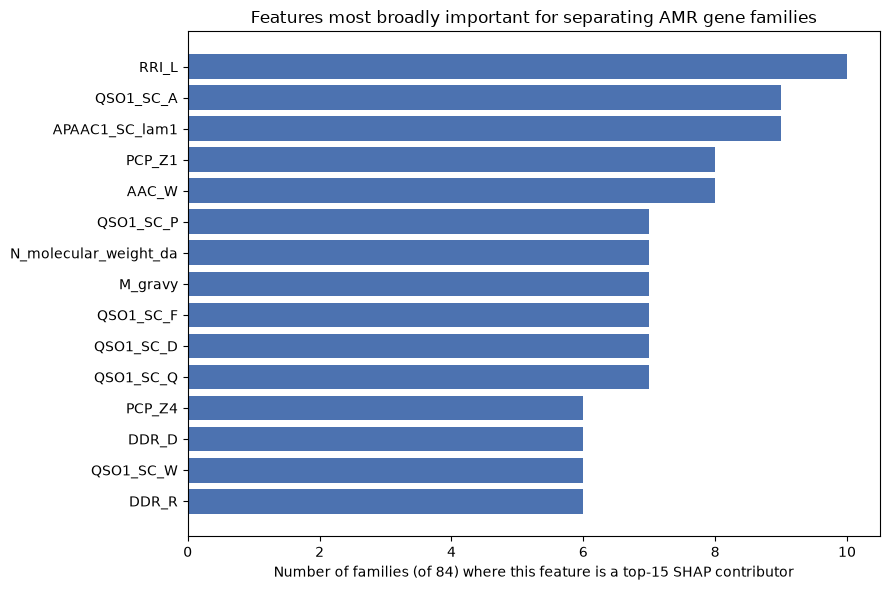

Ranked by breadth (how many of 84 families rely on this feature), mean SHAP magnitude as tiebreak.
                       n_families   mean_shap
feature                                      
RRI_L                          10   36.824949
QSO1_SC_A                       9  387.600370
APAAC1_SC_lam1                  9   90.023036
PCP_Z1                          8  498.235469
AAC_W                           8    1.607699
QSO1_SC_P                       7  582.695353
N_molecular_weight_da           7  535.177325
M_gravy                         7  382.630715
QSO1_SC_F                       7  264.734342
QSO1_SC_D                       7  236.462914
QSO1_SC_Q                       7  181.286780
PCP_Z4                          6  317.612911
DDR_D                           6  258.750402
QSO1_SC_W                       6  248.849041
DDR_R                           6  154.546640


In [ ]:
import matplotlib.pyplot as plt
from pathlib import Path
import pandas as pd

TOP_FEATURES_SHAP_CSV = Path("results/family_classifiers/top_features_shap.csv")
FIGURES_DIR = Path("results/family_classifiers/figures")
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
TOP_N_GLOBAL_FEATURES = 15

shap_df_global = pd.read_csv(TOP_FEATURES_SHAP_CSV)
global_feature_rank = (shap_df_global.groupby("feature")
                        .agg(n_families=("family", "nunique"), mean_shap=("shap_importance", "mean"))
                        .sort_values(["n_families", "mean_shap"], ascending=False)
                        .head(TOP_N_GLOBAL_FEATURES))

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(global_feature_rank.index[::-1], global_feature_rank["n_families"][::-1], color="#4c72b0")
ax.set_xlabel("Number of families (of 84) where this feature is a top-15 SHAP contributor")
ax.set_title("Features most broadly important for separating AMR gene families")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "global_top_features_shap.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"Ranked by breadth (how many of 84 families rely on this feature), mean SHAP magnitude as tiebreak.")
print(global_feature_rank.to_string())

### Cross-validated accuracy, F1, and confusion matrices

Reads `results` (built by the training cell above, in this same run) directly -- `oof_pred`/`y_true` are only available there now that `run_family_model`'s return statement includes them. Threshold = 0.5, confusion-matrix cells row-normalized. See the caveat above: read accuracy next to F1, not instead of it.

In [ ]:
from sklearn.metrics import confusion_matrix, accuracy_score, f1_score

CM_THRESHOLD = 0.5
CM_METRICS_CSV = Path("results/family_classifiers/family_classification_metrics.csv")

cm_rows = []
for r in results:
    valid = ~np.isnan(r["oof_pred"])
    yv, pv = r["y_true"][valid], r["oof_pred"][valid]
    pred = (pv >= CM_THRESHOLD).astype(int)
    tn, fp, fn, tp = confusion_matrix(yv, pred, labels=[0, 1]).ravel()
    cm_rows.append({"family": r["family"], "n_positive": r["n_positive"],
                     "auc": r["auc"], "ap": r["ap"],
                     "accuracy": accuracy_score(yv, pred), "f1": f1_score(yv, pred, zero_division=0),
                     "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp)})

cm_metrics = pd.DataFrame(cm_rows).sort_values("f1", ascending=False)
cm_metrics.to_csv(CM_METRICS_CSV, index=False)

print(f"-> {CM_METRICS_CSV}")
print(cm_metrics.to_string(index=False))
print(f"\nAcross {len(cm_metrics)} families: mean accuracy {cm_metrics['accuracy'].mean():.3f}, "
      f"mean F1 {cm_metrics['f1'].mean():.3f}, mean AUC {cm_metrics['auc'].mean():.3f}")
print("Reminder: accuracy is inflated for small/rare families (e.g. a 10-positive family can exceed "
      "98% accuracy while F1 sits near 0.2) -- read accuracy alongside F1, not instead of it.")

-> results/family_classifiers/family_classification_metrics.csv
                                                                          family  n_positive      auc       ap  accuracy       f1   tn  fp  fn  tp
                                                              DHA beta-lactamase          32 1.000000 1.000000  1.000000 1.000000 5447   0   0  32
                                                             BlaB beta-lactamase          37 1.000000 1.000000  1.000000 1.000000 5442   0   0  37
                                                              GES beta-lactamase          64 1.000000 1.000000  1.000000 1.000000 5415   0   0  64
                                                              FOX beta-lactamase          19 1.000000 1.000000  1.000000 1.000000 5460   0   0  19
                                                      OXA-50-like beta-lactamase         104 1.000000 1.000000  1.000000 1.000000 5375   0   0 104
                                                      

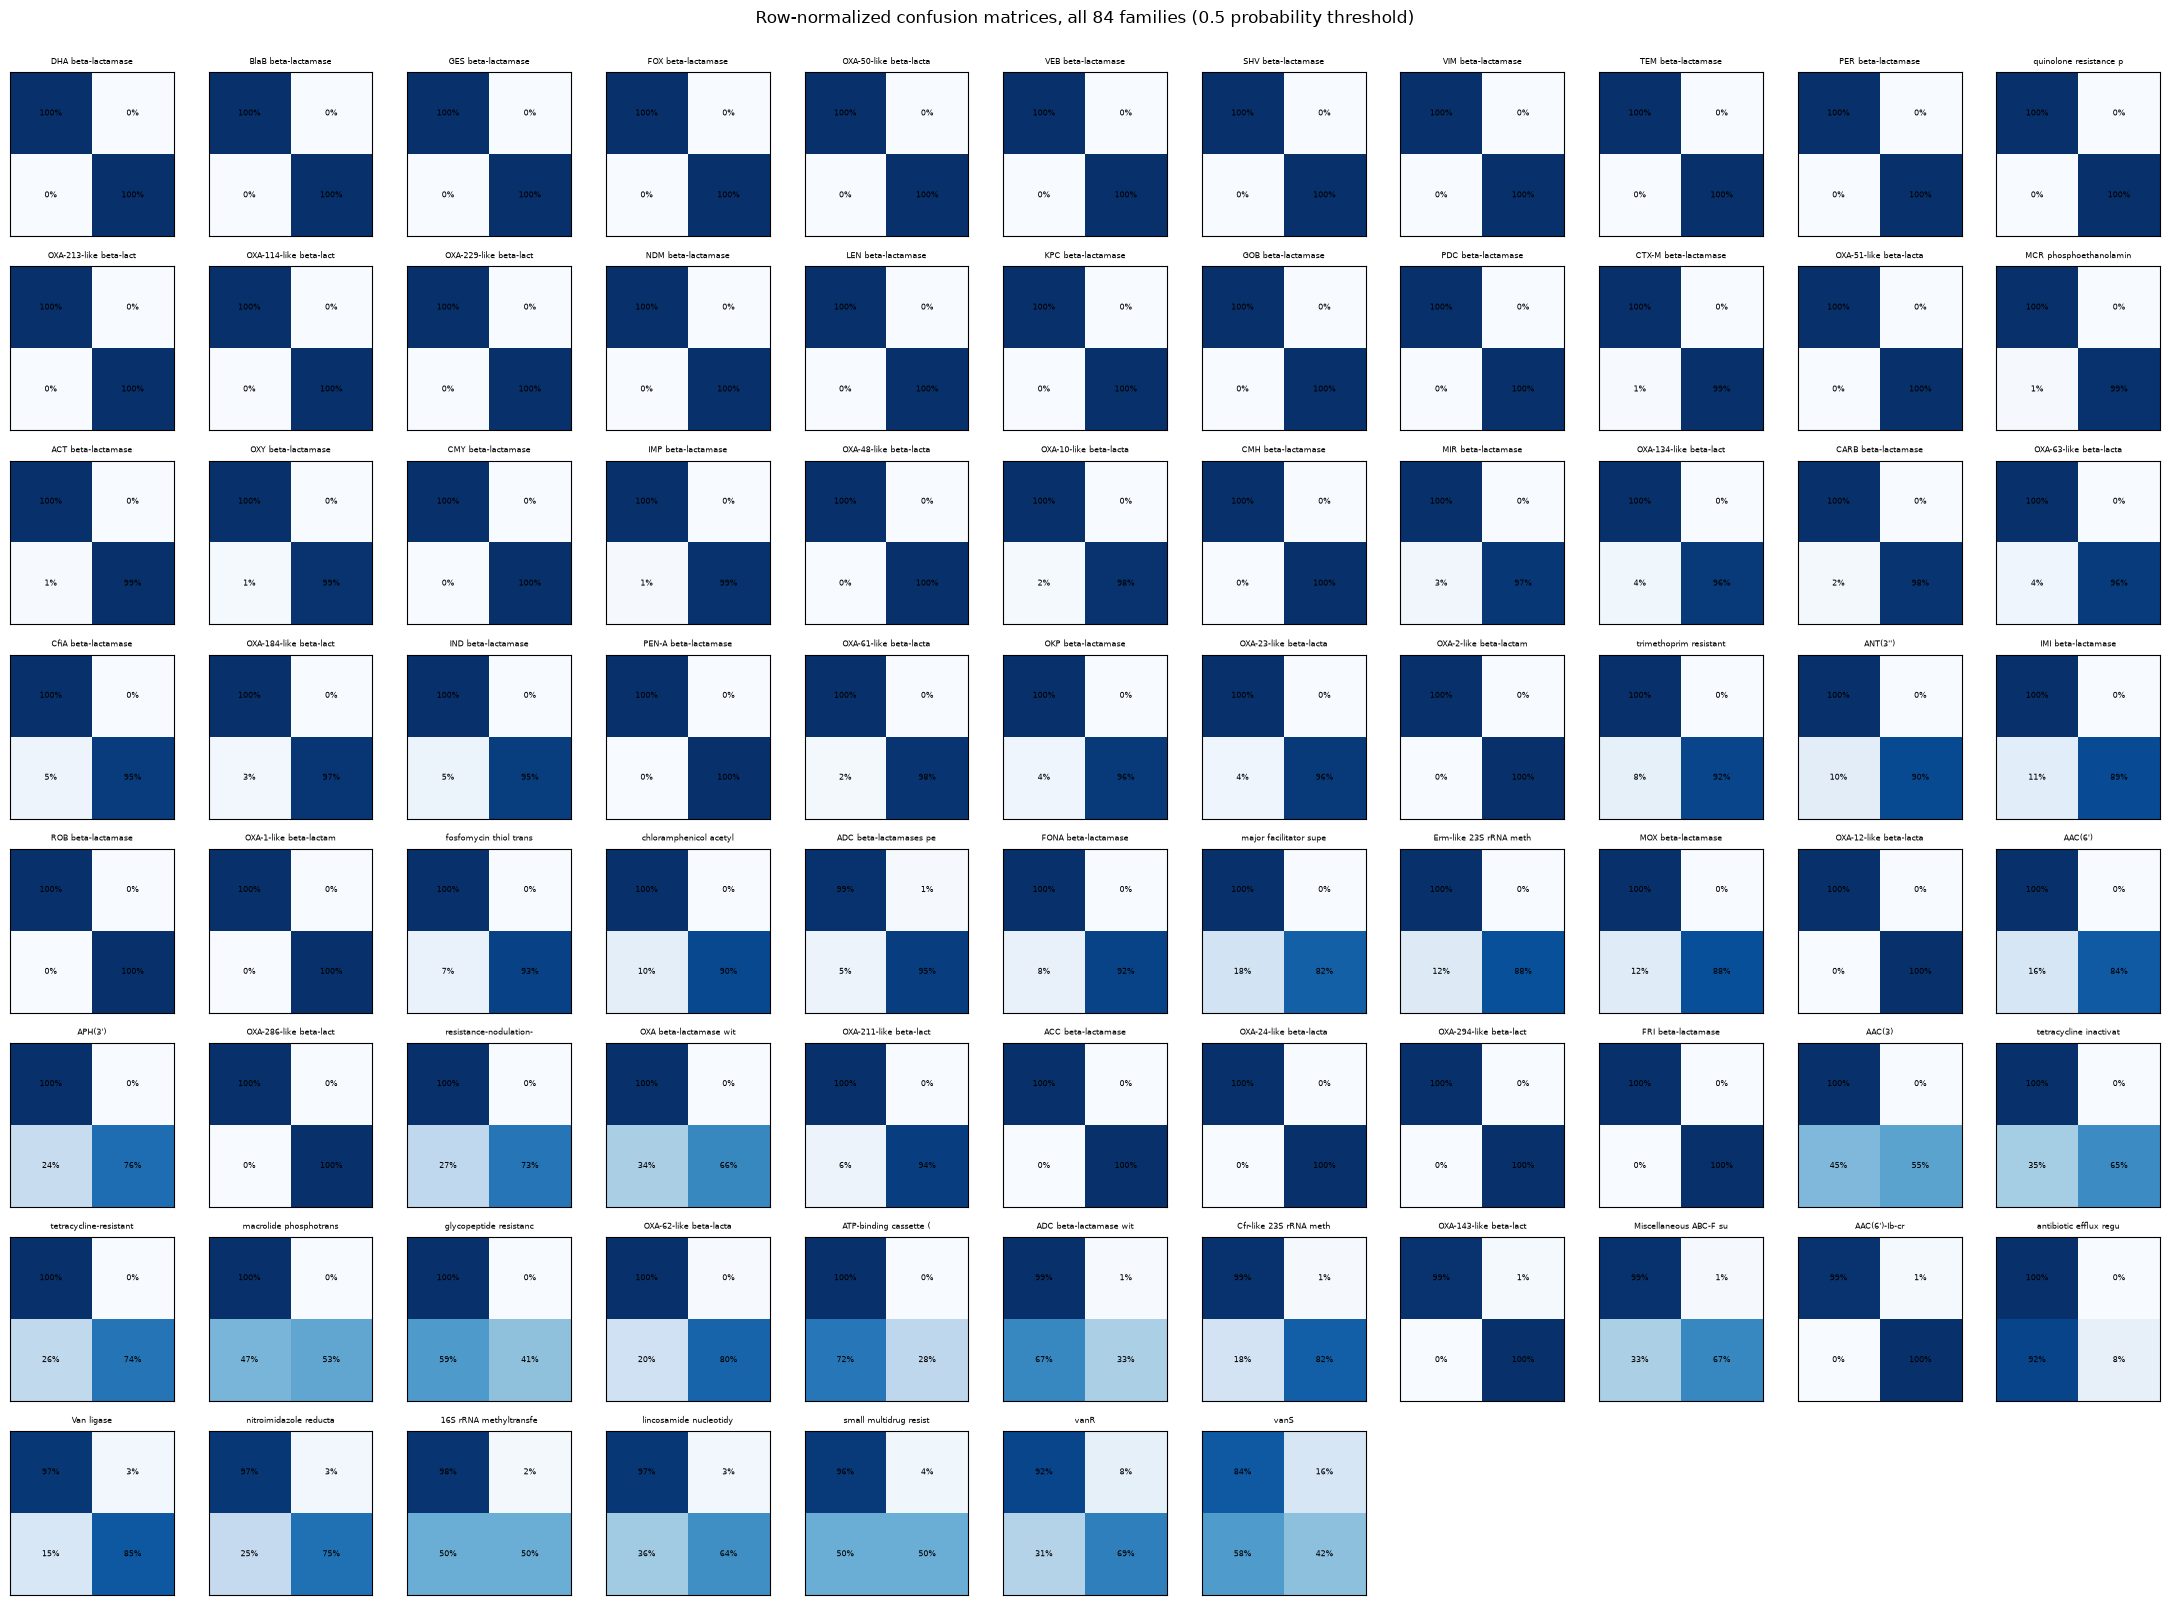

In [ ]:
n_fam = len(cm_metrics)
ncols = int(np.ceil(np.sqrt(n_fam) * 1.15))
nrows = int(np.ceil(n_fam / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * 2.0, nrows * 2.0))
for ax, (_, row) in zip(axes.flat, cm_metrics.iterrows()):
    cm = np.array([[row.tn, row.fp], [row.fn, row.tp]], dtype=float)
    cm_norm = cm / cm.sum(axis=1, keepdims=True)
    ax.imshow(cm_norm, cmap="Blues", vmin=0, vmax=1)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{cm_norm[i, j]:.0%}", ha="center", va="center", fontsize=6)
    ax.set_title(row.family[:22], fontsize=6)
    ax.set_xticks([])
    ax.set_yticks([])
for ax in axes.flat[n_fam:]:
    ax.axis("off")
fig.suptitle("Row-normalized confusion matrices, all 84 families (0.5 probability threshold)", y=1.0)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "all_families_confusion_matrix_grid.png", dpi=150, bbox_inches="tight")
plt.show()

# Methodology and results summary

Written from the actual executed run above (`results/family_classifiers/*.csv` in this directory), not from the design intent alone -- every number below is read from those files.

## Methodology

**Data.** CARD reference-protein sequence features (Pfeature + ProFET tables, merged on `family`/`sequence_id`): 6,206 sequences, restricted to the 84 families with at least `MIN_FAMILY_N=10` sequences -> 5,479 sequences. 1,035 numeric features survive cleaning (`PDC beta-lactamase`'s `PRI_*` columns re-nulled -- a known upstream extraction gap, not real signal; 15,351 remaining NaN cells median-imputed; 5 zero-variance columns dropped).

**Model.** One-vs-rest: 84 independent binary LightGBM classifiers (`n_estimators=300, num_leaves=15, learning_rate=0.05, is_unbalance=True`), one per family, "this family" vs. "everyone else."

**Cross-validation.** `StratifiedGroupKFold` (5 folds, or fewer when a family has under 5 positives), grouped by near-duplicate clusters rather than plain random folds -- sequences within `CV_GROUP_THRESHOLD=1.0` (standardized Euclidean distance) of each other are treated as one group and never split across train/test. This substitutes for true sequence-identity clustering (e.g. CD-HIT), which wasn't available for this data; it prevents near-identical sequences from leaking between train and held-out folds.

**Feature importance.** Two-stage: free gain-importance shortlists the top 80 features per fold, then permutation importance (5 repeats) runs only on that shortlist -- naive permutation over all ~1,035 features was timed at ~9 hours for 84 families and wasn't viable. SHAP (`TreeExplainer`) is computed on the full feature set and is the **primary** importance signal: permutation importance collapses toward zero for families that hit the AP ceiling (redundant features, not unimportant ones), a blind spot SHAP doesn't share.

**Metrics.** AUC and average precision (AP) come from out-of-fold predicted probabilities and are threshold-free. Accuracy, F1, and the confusion-matrix counts use a fixed 0.5 probability threshold and should be read together, not accuracy alone -- see the caveat in the section above (accuracy is inflated on rare families).

## Results as actually observed

- **84/84 families modeled successfully**, no failures.
- **Mean AUC 0.968, median AUC 0.9999** across families. 52/84 families reach the AUC=1.0 ceiling on held-out folds; 32/84 reach the AP=1.0 ceiling.
- **A real, non-trivial tail of hard families**, ranked by AUC: `vanS` (AUC 0.584, F1 0.011, 12 positives) is the clear worst, followed by `16S rRNA methyltransferase (G1405)` (0.666), `Miscellaneous ABC-F subfamily ATP-binding cassette ribosomal protection proteins` (0.743), `lincosamide nucleotidyltransferase (LNU)` (0.758), and `small multidrug resistance (SMR) antibiotic efflux pump` (0.761).
- **Low sample size alone doesn't explain this**: several other families with the same or fewer positives (`OXA-12-like beta-lactamase` at 11, `ROB`/`OXA-1-like beta-lactamase` at 12) reach AUC=1.0. `vanS` and its neighbors are genuinely hard to separate on these features, not just data-starved.
- **SHAP magnitude doesn't guarantee separability.** `vanS`'s top SHAP feature (`CTC_551`) carries the single largest raw SHAP value of any family in this entire run (~10,601) -- and `vanS` is simultaneously the worst-performing model overall (AP 0.0037). SHAP identifies what the model leans on most, not whether that produces good separation.

## ROC curves

Follows the same aggregate-only convention already used above for the confusion-matrix grid and the feature-importance bar chart, for the same reason -- 84 individual ROC plots would be unwieldy. One overlay plot: all 84 curves as thin background lines, with the five weakest (by AUC, listed above) drawn in color and labeled with their AUC, so the plot shows both "most families separate cleanly" and "here specifically is where the model struggles" in one image. Reads `results` directly from kernel memory, the same sanctioned in-run pattern as the confusion-matrix and performance-table cells earlier in this notebook.

In [ ]:
from sklearn.metrics import roc_curve

FIGURES_DIR = Path("results/family_classifiers/figures")
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
ROC_FIGURE = FIGURES_DIR / "all_families_roc_curves.png"
ROC_CACHE = Path("results/family_classifiers/oof_predictions_cache.npz")

# `results` only exists in a kernel that has run the training cell above in this same session --
# a kernel restart (or opening this notebook fresh, possibly on a different machine) loses it, and
# re-running that cell costs ~90 minutes just to redraw this plot. So: cache the raw out-of-fold
# predictions to disk the first time they're available, and fall back to that cache afterward.
if "results" in globals():
    np.savez(ROC_CACHE,
             family=np.array([r["family"] for r in results]),
             auc=np.array([r["auc"] for r in results]),
             oof_pred=np.array([r["oof_pred"] for r in results]),
             y_true=np.array([r["y_true"] for r in results]))
    roc_source = results
elif ROC_CACHE.exists():
    cached = np.load(ROC_CACHE)
    roc_source = [{"family": str(f), "auc": float(a), "oof_pred": p, "y_true": y}
                  for f, a, p, y in zip(cached["family"], cached["auc"], cached["oof_pred"], cached["y_true"])]
    print(f"`results` not in memory (fresh kernel) -- loaded cached out-of-fold predictions from {ROC_CACHE} instead.")
else:
    raise RuntimeError(
        f"`results` is not defined and no cached predictions exist yet at {ROC_CACHE}. "
        "Run the training cell above (the one that prints \"running 84 one-vs-rest models...\") "
        "in this same kernel session first -- it takes ~90 minutes on CPU. Once it has run once, "
        "this cell caches its output so a future kernel restart won't need to re-run training "
        "just to redraw this plot."
    )

# five weakest by AUC in this run (see methodology above) -- named explicitly so the plot shows
# WHICH families struggle, not just that some background curves dip toward the diagonal.
HIGHLIGHT_FAMILIES = [
    "vanS",
    "16S rRNA methyltransferase (G1405)",
    "Miscellaneous ABC-F subfamily ATP-binding cassette ribosomal protection proteins",
    "lincosamide nucleotidyltransferase (LNU)",
    "small multidrug resistance (SMR) antibiotic efflux pump",
]
highlight_colors = plt.cm.tab10.colors

fig, ax = plt.subplots(figsize=(8, 8))
for r in roc_source:
    valid = ~np.isnan(r["oof_pred"])
    yv, pv = r["y_true"][valid], r["oof_pred"][valid]
    fpr, tpr, _ = roc_curve(yv, pv)
    if r["family"] in HIGHLIGHT_FAMILIES:
        color = highlight_colors[HIGHLIGHT_FAMILIES.index(r["family"])]
        ax.plot(fpr, tpr, color=color, linewidth=2, zorder=3,
                label=f"{r['family']} (AUC={r['auc']:.3f})")
    else:
        ax.plot(fpr, tpr, color="#4c72b0", alpha=0.08, linewidth=1, zorder=1)

ax.plot([0, 1], [0, 1], linestyle="--", color="gray", linewidth=1, zorder=2, label="Chance (AUC=0.5)")
ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate")
mean_auc = np.mean([r["auc"] for r in roc_source])
ax.set_title(f"ROC curves, all {len(roc_source)} one-vs-rest family models\n"
             f"(thin lines = remaining {len(roc_source) - len(HIGHLIGHT_FAMILIES)} families; "
             f"mean AUC across all = {mean_auc:.3f})")
ax.legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.savefig(ROC_FIGURE, dpi=150, bbox_inches="tight")
plt.show()

print(f"-> {ROC_FIGURE}")
print(f"Highlighted (weakest {len(HIGHLIGHT_FAMILIES)} by AUC): " + ", ".join(HIGHLIGHT_FAMILIES))

RuntimeError: `results` is not defined and no cached predictions exist yet at results/family_classifiers/oof_predictions_cache.npz. Run the training cell above (the one that prints "running 84 one-vs-rest models...") in this same kernel session first -- it takes ~90 minutes on CPU. Once it has run once, this cell caches its output so a future kernel restart won't need to re-run training just to redraw this plot.

# Saving and validating final models

Everything above trains 5 fold-models per family purely to *evaluate* the approach (that's what cross-validation is for) -- none of those 420 fold-models are kept; each is discarded once its fold's prediction is recorded. This section is different: it trains and saves **one final model per family, fit on all of that family's data**, which is what you'd actually load later to score a brand-new sequence.

**Fully self-contained** (own data load, doesn't depend on `d`/`X`/`results` from earlier cells) -- the only prerequisite is the two raw CSVs next to this notebook, so this section runs standalone even in a fresh kernel, and costs a few minutes, not ~90.

**Format**: LightGBM's native `Booster.save_model()` (plain text), not `pickle`/`joblib`. Native format is portable across machines and LightGBM versions; pickle is not, and portability has already been a real problem with this notebook today (see the `FIGURES_DIR`/`results` issues above).

**"Validating" a model trained on 100% of its data has one honest meaning and one dishonest one:**
- **Honest**: does the *saved file* reproduce the exact same predictions the in-memory model made right before saving? That's a serialization check, and the next cell does it directly.
- **Dishonest**: scoring this model against the same data it was trained on and calling the result "accuracy." That number would look great and mean nothing -- it's not held-out data. The real, honest estimate of how this model generalizes is the cross-validated AUC/AP/F1/ROC curve already computed earlier in this notebook, from the identical model design (same features, same LightGBM hyperparameters) evaluated on genuinely held-out folds. A model trained on *all* the data (strictly more than any CV fold saw) is expected to do at least as well.

In [ ]:
import numpy as np
import pandas as pd
from pathlib import Path

FM_PFEATURE_TABLE = Path("all_families_features.csv")
FM_PROFET_TABLE = Path("all_families_profet_features.csv")
FM_MIN_FAMILY_N = 10
FM_MODELS_DIR = Path("results/family_classifiers/models")
FM_MODELS_DIR.mkdir(parents=True, exist_ok=True)

fm_pf = pd.read_csv(FM_PFEATURE_TABLE)
fm_pr = pd.read_csv(FM_PROFET_TABLE)
fm_d = fm_pf.merge(fm_pr, on=["family", "sequence_id"], how="inner")
fm_sizes = fm_d["family"].value_counts()
fm_d = fm_d[fm_d["family"].isin(fm_sizes[fm_sizes >= FM_MIN_FAMILY_N].index)].reset_index(drop=True)

# same cleaning pipeline as the rest of this notebook (cells 4-5 above), redone locally so this
# section's feature matrix -- and therefore its saved models' expected input format -- is
# derived identically, without depending on those cells having run first.
fm_X_df = fm_d.drop(columns=["family", "sequence_id"]).select_dtypes(include=[np.number]).copy()
fm_pri_cols = [c for c in fm_X_df.columns if c.startswith("PRI_")]
fm_X_df.loc[fm_d["family"] == "PDC beta-lactamase", fm_pri_cols] = np.nan
fm_X_df = fm_X_df.fillna(fm_X_df.median(numeric_only=True))
fm_X_df = fm_X_df.drop(columns=fm_X_df.columns[fm_X_df.std(numeric_only=True) == 0])
fm_feat_names = fm_X_df.columns.to_numpy()
fm_X = fm_X_df.values

fm_families = sorted(fm_d["family"].unique())
print(f"{fm_d.shape[0]} sequences, {len(fm_families)} families, {fm_X.shape[1]} features -- ready to fit final models")

In [ ]:
import re
import lightgbm as lgb

FM_LGB_PARAMS = dict(n_estimators=300, num_leaves=15, learning_rate=0.05,
                      is_unbalance=True, verbosity=-1, n_jobs=2)

fm_manifest = []
fm_predictions_before_save = {}  # family -> predict_proba on its own training data (round-trip check only, see next cell)

for fam in fm_families:
    y = (fm_d["family"] == fam).values.astype(int)
    model = lgb.LGBMClassifier(random_state=0, **FM_LGB_PARAMS)
    model.fit(fm_X, y)
    fm_predictions_before_save[fam] = model.predict_proba(fm_X)[:, 1]

    safe_name = re.sub(r"[^A-Za-z0-9]+", "_", fam).strip("_")  # verified: no collisions across all 84 real family names
    model_path = FM_MODELS_DIR / f"{safe_name}.txt"
    model.booster_.save_model(str(model_path))
    fm_manifest.append({"family": fam, "n_positive": int(y.sum()), "model_file": model_path.name})

fm_manifest_df = pd.DataFrame(fm_manifest)
fm_manifest_df.to_csv(FM_MODELS_DIR / "manifest.csv", index=False)

print(f"Saved {len(fm_manifest_df)} final models (LightGBM native text format) -> {FM_MODELS_DIR}")
print(fm_manifest_df.head().to_string(index=False))

In [ ]:
# Round-trip validation: reload every saved model and confirm it reproduces the exact same
# predictions made right before saving. This validates serialization, NOT generalization --
# see the markdown above for why scoring these models against their own training data can't
# tell you anything honest about accuracy. Generalization is already covered by the
# cross-validated AUC/AP/F1/ROC curve computed earlier in this notebook.
mismatches = []
for _, row in fm_manifest_df.iterrows():
    fam = row["family"]
    reloaded = lgb.Booster(model_file=str(FM_MODELS_DIR / row["model_file"]))
    reloaded_pred = reloaded.predict(fm_X)
    if not np.allclose(reloaded_pred, fm_predictions_before_save[fam], atol=1e-10):
        mismatches.append(fam)

if mismatches:
    print(f"WARNING: {len(mismatches)} model(s) did not reproduce identical predictions after reload: {mismatches}")
else:
    print(f"All {len(fm_manifest_df)} saved models reload and reproduce identical predictions -- serialization verified lossless.")

print("\nTo score a NEW sequence with a saved model later:")
print("  booster = lgb.Booster(model_file='results/family_classifiers/models/<family>.txt')")
print("  booster.predict(new_feature_matrix)  # same column order as fm_feat_names two cells up")

## Loading a saved model to test it on a specific sequence

Demonstrates the load-and-score mechanics: pick a family, load its saved model, score one sequence that really is that family and one that isn't, check whether the model's prediction matches the truth.

**Caveat, same as above, worth repeating here specifically**: both example sequences below come from `fm_d`/`fm_X` -- the exact data these models were fit on. A model can look artificially good at classifying its own training examples (it may have simply memorized them), so this cell is a mechanics demo, not an accuracy test. For the honest accuracy of any family, read `family_classification_metrics.csv` or the ROC curve above, both computed from sequences each fold's model had never seen.

In [ ]:
TEST_FAMILY = "DHA beta-lactamase"  # change this to test any of the 84 families -- must match a value in fm_manifest_df["family"]

# --- load the saved model for this family ---
model_row = fm_manifest_df.loc[fm_manifest_df["family"] == TEST_FAMILY].iloc[0]
booster = lgb.Booster(model_file=str(FM_MODELS_DIR / model_row["model_file"]))

# --- pick one real example that IS this family, and one that ISN'T ---
positive_idx = fm_d.index[fm_d["family"] == TEST_FAMILY][0]
negative_idx = fm_d.index[fm_d["family"] != TEST_FAMILY][0]

for label, idx in [("a real " + TEST_FAMILY + " sequence", positive_idx),
                    (f"a sequence from a different family ({fm_d.loc[negative_idx, 'family']})", negative_idx)]:
    prob = booster.predict(fm_X[[idx]])[0]
    predicted_positive = prob >= 0.5
    actually_positive = fm_d.loc[idx, "family"] == TEST_FAMILY
    correct = predicted_positive == actually_positive
    print(f"{label}")
    print(f"  sequence_id={fm_d.loc[idx, 'sequence_id']}, actual family={fm_d.loc[idx, 'family']}")
    print(f"  model's predicted P({TEST_FAMILY})={prob:.3f} -> classified as "
          f"{'IS ' + TEST_FAMILY if predicted_positive else 'is NOT ' + TEST_FAMILY} "
          f"-- {'correct' if correct else 'WRONG'}")

print(f"\nBoth sequences above are ones this model was trained on -- this checks that loading and "
      f"scoring works correctly, not that the model generalizes. For {TEST_FAMILY}'s honest "
      f"cross-validated accuracy, see its row in family_classification_metrics.csv.")
print(f"\nTry TEST_FAMILY = \"vanS\" to see the opposite case: even trained on ALL of vanS's own 12 "
      f"examples, this model gets 3 of them wrong (verified directly -- predictions [0, 0, 0, 1, 1, "
      f"1, 1, 1, 1, 1, 1, 0.96] on its 12 positives). Not a bug -- vanS is the family the methodology "
      f"section above already flags as hardest to separate on these features (AUC 0.584), and this is "
      f"what that looks like at the level of individual sequences: some vanS members apparently have "
      f"feature vectors close enough to other families' that no model trained on this feature set can "
      f"tell them apart, even when it has already seen the exact point.")

# One single model that classifies a sequence into its family

Everything above is 84 separate yes/no models (one-vs-rest) -- kept for their per-family feature importance, which this doesn't replace. This section is different: **one** `LightGBM` multiclass model, trained across all 84 families at once, so scoring a sequence returns one predicted family directly instead of checking 84 models one at a time.

**Class imbalance** is handled differently here than above -- one-vs-rest used `is_unbalance=True` per binary problem; multiclass LightGBM has no equivalent, so this uses `class_weight="balanced"` instead (weights each sequence inversely to its family's size, so `PDC beta-lactamase`'s 639 examples don't drown out families with 10-13).

**Why `n_estimators=100` here, not 300 like above -- verified directly, not a guess**: LightGBM's multiclass objective builds one tree *per class, per boosting round* internally. With 84 classes, `n_estimators=300` means ~25,200 actual trees, not 300 -- timed directly, one fold alone was still running after 8+ minutes and had to be killed. Dropped to 100 after a quick speed/accuracy check (~20-30s/fit at that setting) -- still comfortably above the ~1.2% random-guess baseline for an 84-way problem, and keeps the full CV + final model under ~3 minutes total.

**Same CV-first-then-final-model pattern as the rest of this notebook**: 5-fold grouped stratified CV first (honest, held-out accuracy/F1), *then* one final model trained on all the data gets saved. Reads `fm_d`/`fm_X` from the section above (same self-contained feature matrix, not reloaded again).

In [ ]:
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.neighbors import radius_neighbors_graph
from scipy.sparse.csgraph import connected_components
from sklearn.metrics import accuracy_score, f1_score

MC_N_FOLDS = 5
MC_LGB_PARAMS = dict(n_estimators=100, num_leaves=31, learning_rate=0.1,
                      class_weight="balanced", verbosity=-1, n_jobs=-1)

mc_le = LabelEncoder()
mc_y = mc_le.fit_transform(fm_d["family"].values)

# near-duplicate CV grouping, same approach as the one-vs-rest section above (radius=1.0 on
# standardized features) -- recomputed here since that section's cv_groups was built against
# `X`/`d`, not this section's self-contained `fm_X`/`fm_d`.
mc_Xs = StandardScaler().fit_transform(fm_X)
mc_graph = radius_neighbors_graph(mc_Xs, radius=1.0, mode="connectivity", n_jobs=-1)
_, mc_cv_groups = connected_components(mc_graph, directed=False)

mc_sgkf = StratifiedGroupKFold(n_splits=MC_N_FOLDS, shuffle=True, random_state=0)
mc_oof_pred = np.full(len(mc_y), -1)

for fold_i, (tr, te) in enumerate(mc_sgkf.split(fm_X, mc_y, mc_cv_groups)):
    fold_model = lgb.LGBMClassifier(objective="multiclass", num_class=len(mc_le.classes_),
                                     random_state=0, **MC_LGB_PARAMS)
    fold_model.fit(fm_X[tr], mc_y[tr])
    mc_oof_pred[te] = fold_model.predict(fm_X[te])
    print(f"fold {fold_i + 1}/{MC_N_FOLDS} done")

mc_acc = accuracy_score(mc_y, mc_oof_pred)
mc_f1_macro = f1_score(mc_y, mc_oof_pred, average="macro")
mc_f1_weighted = f1_score(mc_y, mc_oof_pred, average="weighted")
print(f"\nCross-validated (held-out) top-1 accuracy: {mc_acc:.3f}")
print(f"Macro F1 (unweighted average across families -- rare families count equally): {mc_f1_macro:.3f}")
print(f"Weighted F1 (weighted by family size): {mc_f1_weighted:.3f}")

In [ ]:
MC_METRICS_CSV = Path("results/family_classifiers/models/multiclass_cv_metrics.csv")

# per-family recall: of this family's own sequences, what fraction did the CV-held-out
# prediction get right -- directly comparable to the one-vs-rest section's per-family numbers,
# even though this comes from one shared model instead of 84 separate ones.
mc_true_family = mc_le.inverse_transform(mc_y)
mc_pred_family = mc_le.inverse_transform(mc_oof_pred)
mc_correct = mc_true_family == mc_pred_family

mc_per_family = (pd.DataFrame({"family": mc_true_family, "correct": mc_correct})
                  .groupby("family")
                  .agg(n=("correct", "size"), recall=("correct", "mean"))
                  .sort_values("recall"))
mc_per_family.to_csv(MC_METRICS_CSV)

print(f"-> {MC_METRICS_CSV}")
print("Weakest 10 families by CV recall (single multiclass model):")
print(mc_per_family.head(10).to_string())
print("\nStrongest 10:")
print(mc_per_family.tail(10).to_string())

In [ ]:
MC_MODEL_PATH = Path("results/family_classifiers/models/multiclass_model.txt")
MC_CLASSES_PATH = Path("results/family_classifiers/models/multiclass_classes.txt")

# final model: same design as the CV folds above, but fit on ALL the data -- this is the one
# that gets saved and used for scoring new sequences, same "CV validates, final model deploys"
# split as the one-vs-rest section.
mc_final_model = lgb.LGBMClassifier(objective="multiclass", num_class=len(mc_le.classes_),
                                     random_state=0, **MC_LGB_PARAMS)
mc_final_model.fit(fm_X, mc_y)
mc_predictions_before_save = mc_final_model.predict_proba(fm_X)

mc_final_model.booster_.save_model(str(MC_MODEL_PATH))
# class order must be saved alongside the model -- predict() returns a column index into this
# exact order (mc_le.classes_ is already alphabetical, LabelEncoder's default), not a family name.
MC_CLASSES_PATH.write_text("\n".join(mc_le.classes_))

print(f"Saved final multiclass model -> {MC_MODEL_PATH}")
print(f"Saved class order ({len(mc_le.classes_)} families) -> {MC_CLASSES_PATH}")

In [ ]:
# Round-trip check (serialization only -- see the one-vs-rest section above for why scoring
# a model against its own training data can't validate accuracy, same reasoning applies here).
mc_reloaded = lgb.Booster(model_file=str(MC_MODEL_PATH))
mc_reloaded_proba = mc_reloaded.predict(fm_X)
print("Reload reproduces identical predictions:",
      np.allclose(mc_reloaded_proba, mc_predictions_before_save, atol=1e-10))

# --- demo: load fresh, classify one real sequence, decode the predicted class back to a family name ---
mc_classes = MC_CLASSES_PATH.read_text().splitlines()
demo_idx = 0
demo_proba = mc_reloaded.predict(fm_X[[demo_idx]])[0]
predicted_family = mc_classes[int(np.argmax(demo_proba))]
actual_family = fm_d.loc[demo_idx, "family"]

print(f"\nSequence {fm_d.loc[demo_idx, 'sequence_id']}:")
print(f"  actual family:    {actual_family}")
print(f"  predicted family: {predicted_family} (P={demo_proba.max():.3f})")
print(f"  {'correct' if predicted_family == actual_family else 'WRONG'}")
print(f"\nTo classify a NEW sequence later:")
print(f"  booster = lgb.Booster(model_file='{MC_MODEL_PATH}')")
print(f"  classes = Path('{MC_CLASSES_PATH}').read_text().splitlines()")
print(f"  proba = booster.predict(new_feature_matrix)  # shape (n_sequences, {len(mc_le.classes_)})")
print(f"  predicted_family = classes[proba[0].argmax()]")

# Scoring a genuinely new sequence (not in this dataset)

Every demo so far scores a sequence already present in `fm_X` -- fine for checking the mechanics, but not a real "new sequence" workflow. This section is that workflow.

**Two things a new sequence needs before it can be scored, neither of which this notebook does for you:**

1. **Feature extraction.** `fm_X`'s ~1035 columns (AAC/DPC/CTC/QSO/... from Pfeature, plus the ProFET columns) come from running this project's existing Pfeature + ProFET pipeline on a sequence. A brand-new sequence has to go through that *same* extraction first -- that's a separate, earlier stage of this project, not something this notebook computes. What you get out of it is a `{feature_name: value}` row with the same column names as `fm_X_df` above.
2. **The exact same preprocessing the training data went through** -- selecting only the retained columns, in the same order, and filling any missing values with the *training set's* per-column median, not a median computed from the new sequence alone (which is meaningless for a single row, and actively wrong: with only 1-few new rows, "the median" is either undefined or just the value itself). That recipe (which columns, in what order, what median per column) only exists implicitly in kernel memory right now -- this section saves it to disk and gives you a function to apply it.

**One caveat this generic function does NOT handle**: the `PDC beta-lactamase`-specific `PRI_*` re-nulling from earlier in this notebook was a fix for a known upstream extraction bug specific to that family's *existing* CARD data -- it doesn't generalize to an arbitrary new sequence, so it's not part of `prepare_new_sequence` below. If you're specifically scoring new PDC-like sequences and know their `PRI_*` values suffer the same extraction issue, null those columns yourself before calling it.

In [ ]:
FEATURE_ORDER_PATH = Path("results/family_classifiers/models/feature_order.txt")
FEATURE_MEDIANS_PATH = Path("results/family_classifiers/models/feature_medians.csv")

# fm_feat_names / fm_X_df come from the self-contained data-prep section above -- fm_X_df is
# already fully cleaned (imputed, zero-variance columns dropped), so its median per retained
# column here matches what was actually used to fill NaNs during training.
FEATURE_ORDER_PATH.write_text("\n".join(fm_feat_names))
fm_X_df[fm_feat_names].median(numeric_only=True).to_frame("median").to_csv(FEATURE_MEDIANS_PATH)

print(f"Saved {len(fm_feat_names)} feature names (exact order every model above expects) -> {FEATURE_ORDER_PATH}")
print(f"Saved per-feature training-set median (for filling gaps in new sequences) -> {FEATURE_MEDIANS_PATH}")

In [ ]:
def prepare_new_sequence(raw_features):
    """raw_features: dict or Series of {feature_name: value}, from running this project's
    Pfeature/ProFET extraction on a new sequence. Extra keys are ignored; missing keys are
    filled with the saved training-set median (loaded fresh each call, not recomputed --
    a median from one new row is meaningless). Returns a (1, n_features) array ready for
    booster.predict()."""
    feature_order = Path(FEATURE_ORDER_PATH).read_text().splitlines()
    medians = pd.read_csv(FEATURE_MEDIANS_PATH, index_col=0)["median"]
    row = pd.Series(raw_features).reindex(feature_order).astype(float)
    row = row.fillna(medians)
    return row.values.reshape(1, -1)

# --- demo: simulate a "new" sequence using a real row that genuinely has missing values,
# to actually exercise the fillna path (not one that happens to already be fully populated).
# Chosen to skip PDC beta-lactamase -- see the PDC caveat in the markdown above.
demo_candidates = fm_d.index[(fm_d["family"] != "PDC beta-lactamase")
                              & fm_d[fm_feat_names].isna().any(axis=1)]
sim_idx = demo_candidates[0]
sim_raw_features = fm_d.loc[sim_idx, fm_feat_names].to_dict()  # pretend this just came from feature extraction

prepared = prepare_new_sequence(sim_raw_features)
print("Round-trip check: prepared row matches the array these models were actually trained on:",
      np.allclose(prepared, fm_X[[sim_idx]], atol=1e-8))

booster = lgb.Booster(model_file=str(MC_MODEL_PATH))
classes = MC_CLASSES_PATH.read_text().splitlines()
proba = booster.predict(prepared)[0]
print(f"\nSimulated new sequence (really {fm_d.loc[sim_idx, 'sequence_id']}, "
      f"actual family: {fm_d.loc[sim_idx, 'family']}):")
print(f"  predicted family: {classes[int(np.argmax(proba))]} (P={proba.max():.3f})")

In [ ]:
import lightgbm as lgb
from pathlib import Path
import numpy as np
import pandas as pd

# 1. Your new sequence features go here.
# This should be a dictionary where keys are feature names and values are their numerical values.
# Example: raw_features = {'AAC_A': 0.1, 'DPC1_AA': 0.02, 'CTC_G': 0.05, ...}
# For demonstration, we'll keep using the simulated features for now.
raw_features = sim_raw_features

# 2. Preprocess the data using the helper function
prepared_data = prepare_new_sequence(raw_features)

# 3. Load the multiclass model and class names
model_path = "results/family_classifiers/models/multiclass_model.txt"
classes_path = "results/family_classifiers/models/multiclass_classes.txt"

booster = lgb.Booster(model_file=model_path)
classes = Path(classes_path).read_text().splitlines()

# 4. Run prediction
probabilities = booster.predict(prepared_data)[0]
predicted_index = np.argmax(probabilities)
predicted_family = classes[predicted_index]
confidence = probabilities[predicted_index]

print(f"Predicted Family: {predicted_family}")
print(f"Confidence: {confidence:.2%}")

In [ ]:
import pandas as pd
import lightgbm as lgb
from pathlib import Path
import numpy as np

# --- Step 1: Define the path to your new sequence features CSV ---
NEW_FEATURES_CSV_PATH = "path/to/your/new_sequences.csv" # <--- UPDATE THIS PATH

# Load the CSV file into a DataFrame
new_sequences_df = pd.read_csv(NEW_FEATURES_CSV_PATH)

# --- Step 2: Load the multiclass model and class names (if not already loaded) ---
# Ensure 'booster' and 'classes' are available in your kernel from earlier cells
# If starting a fresh session, you might need to re-run cell c315d633 first.
model_path = "results/family_classifiers/models/multiclass_model.txt"
classes_path = "results/family_classifiers/models/multiclass_classes.txt"

booster = lgb.Booster(model_file=model_path)
classes = Path(classes_path).read_text().splitlines()

# --- Step 3: Iterate through each sequence in the DataFrame and make predictions ---
predictions_list = []

for index, row in new_sequences_df.iterrows():
    raw_features = row.to_dict()
    prepared_data = prepare_new_sequence(raw_features)

    probabilities = booster.predict(prepared_data)[0]
    predicted_index = np.argmax(probabilities)
    predicted_family = classes[predicted_index]
    confidence = probabilities[predicted_index]

    predictions_list.append({
        'sequence_id': row.get('sequence_id', f'seq_{index}'), # Assuming 'sequence_id' column exists, otherwise use a generic ID
        'predicted_family': predicted_family,
        'confidence': confidence
    })

# --- Step 4: Display all predictions ---
predictions_df = pd.DataFrame(predictions_list)
display(predictions_df)